In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

#Data:
This data set dates from 1988 and consists of four databases: Cleveland, Hungary, Switzerland, and Long Beach V. It contains 76 attributes, including the predicted attribute, but all published experiments refer to using a subset of 14 of them. The "target" field refers to the presence of heart disease in the patient. It is integer valued 0 = no disease and 1 = disease.

https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset

In [88]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [89]:

df = pd.read_csv('/content/drive/MyDrive/Datasets/heart.csv')
df = df.drop_duplicates().reset_index(drop=True)
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,68,0,2,120,211,0,0,115,0,1.5,1,0,2,1
298,44,0,2,108,141,0,1,175,0,0.6,1,0,2,1
299,52,1,0,128,255,0,1,161,1,0.0,2,1,3,0
300,59,1,3,160,273,0,0,125,0,0.0,2,0,2,0


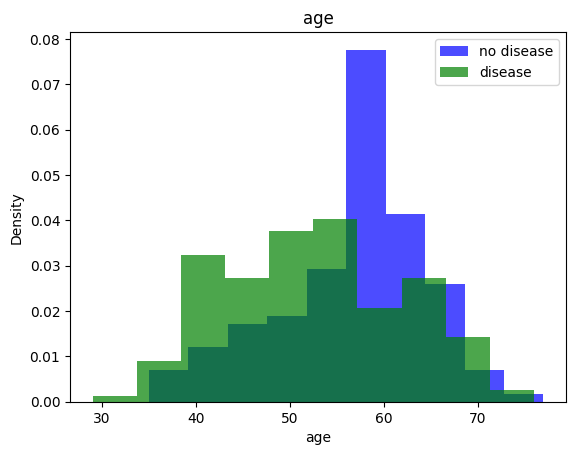

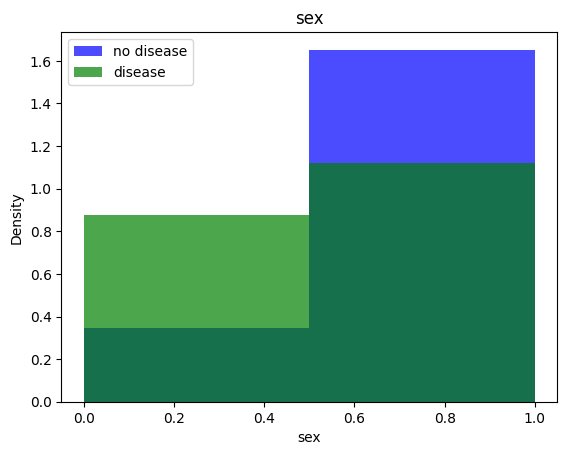

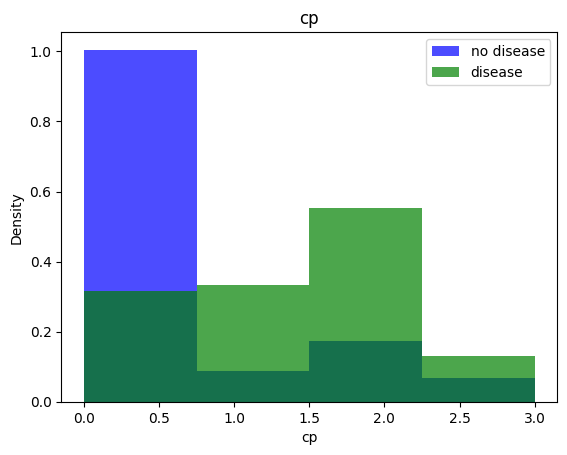

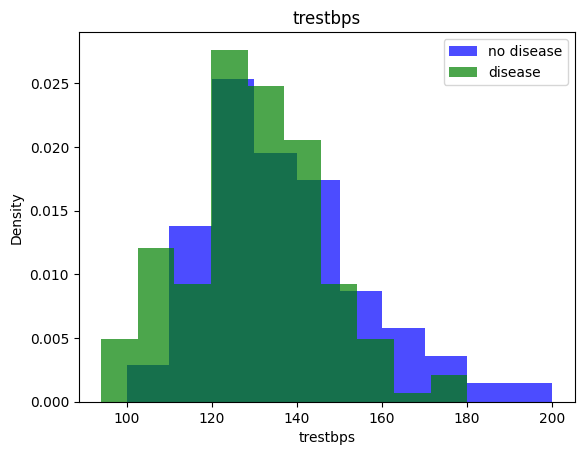

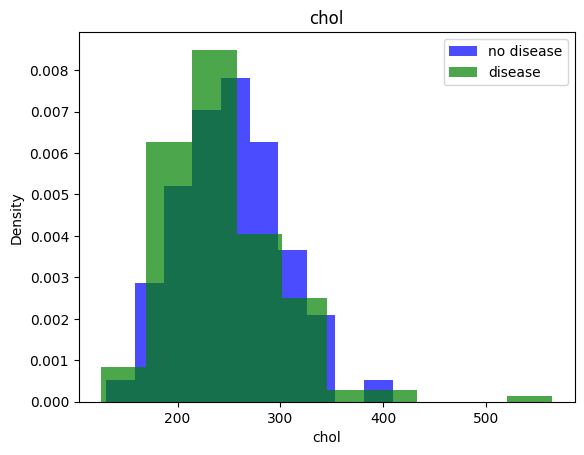

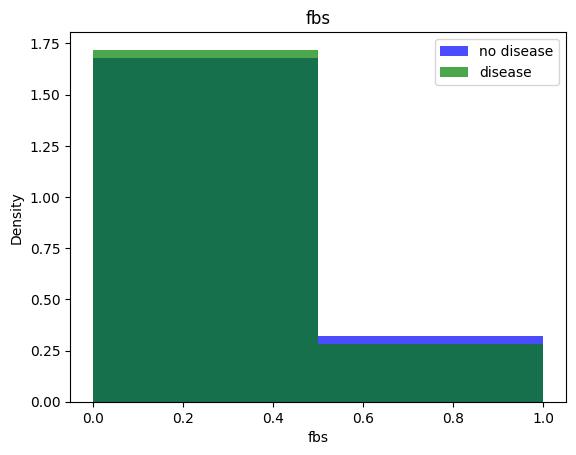

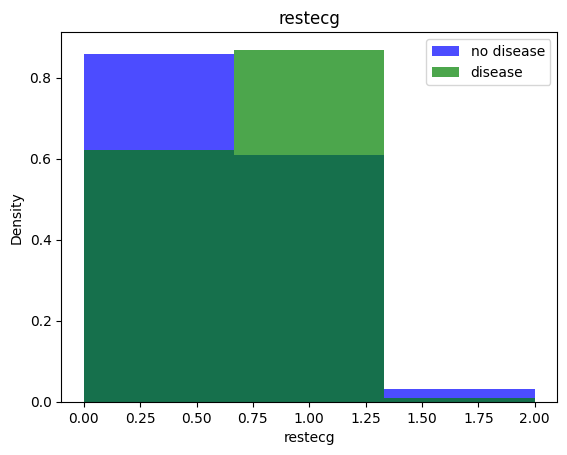

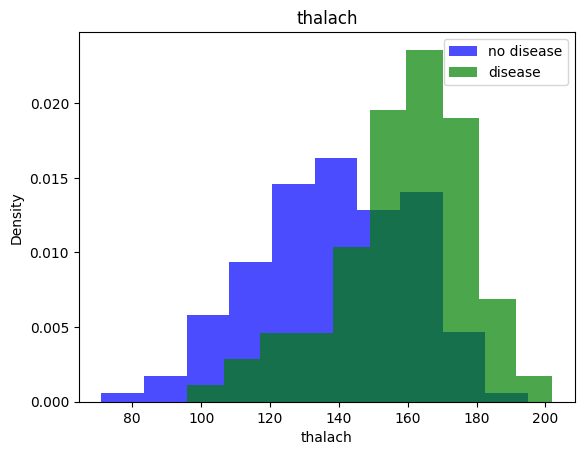

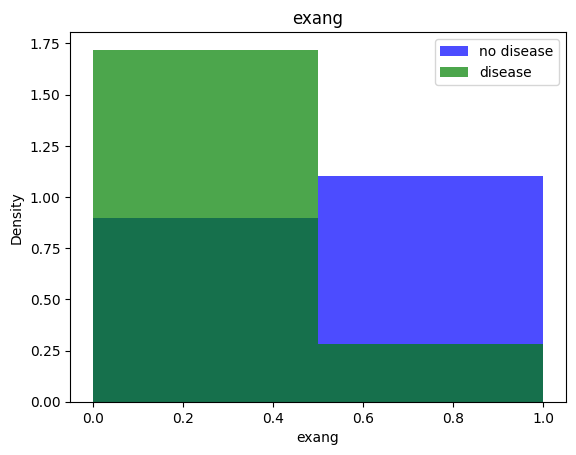

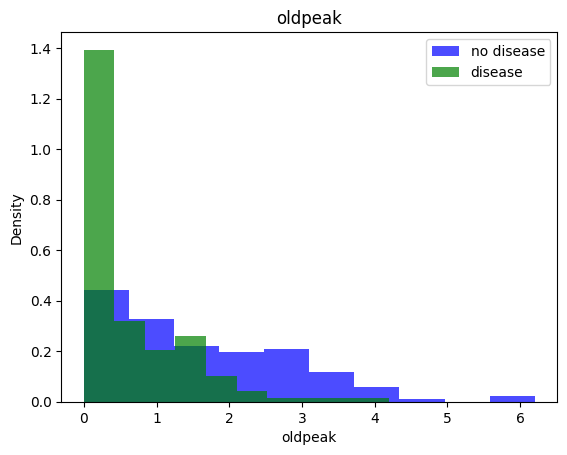

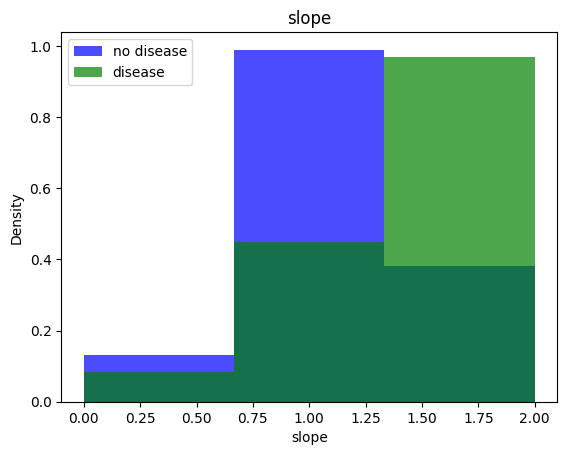

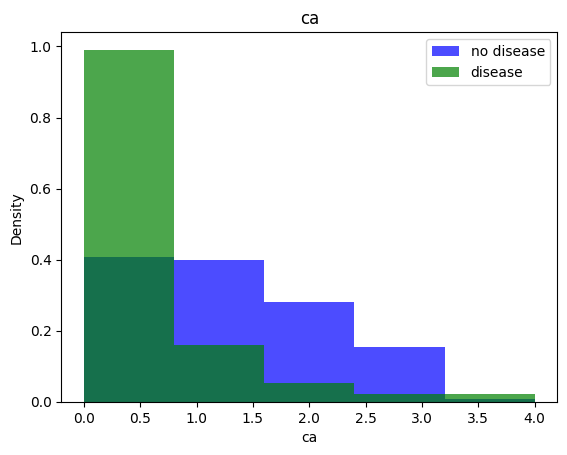

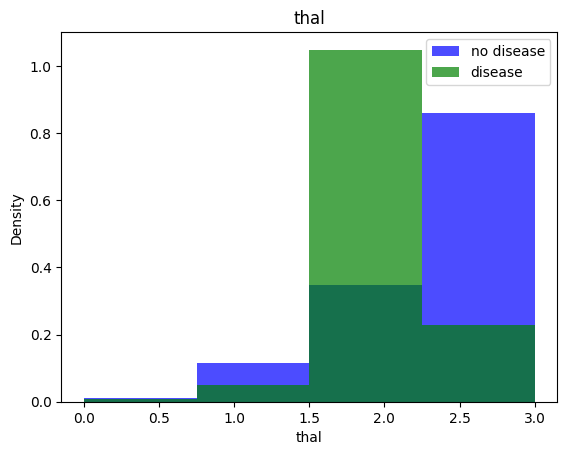

In [90]:
#Tworzymy histogarmy w celu sprawdzenia korelacji danych z wynikiem
for label in df.columns[:-1]:
  liczba_unikatoych_rekordow = df[label].nunique()
  if liczba_unikatoych_rekordow < 10:
    bins = liczba_unikatoych_rekordow
  else:
    bins = 10
  plt.hist(df[df["target"] == 0][label], color='blue', label='no disease', alpha=0.7, density=True, bins = bins)
  plt.hist(df[df["target"] == 1][label], color='green', label='disease', alpha=0.7, density=True, bins = bins)
  plt.title(label)
  plt.ylabel("Density")
  plt.xlabel(label)
  plt.legend()
  plt.show()

#Train, validation, test datasets

In [91]:
shuffled = df.sample(frac = 1, random_state=42)

train = shuffled.iloc[:int(len(shuffled)*0.6)]
validation= shuffled.iloc[int(len(shuffled)*0.6):int(len(shuffled)*0.8)]
test = shuffled.iloc[int(len(shuffled)*0.8):]

In [92]:
def scale_dataset(dataframe):
  X = dataframe[dataframe.columns[:-1]].values
  y = dataframe[dataframe.columns[-1]].values

  scaler = StandardScaler()
  X = scaler.fit_transform(X)

  data = np.hstack((X, np.reshape(y, (-1,1))))

  return data, X, y

In [93]:
#Nie ma potrzeby oversamplować

print(len(train[train["target"] == 0])) #No disease
print(len(train[train["target"] == 1])) #Disease

83
98


In [94]:
train, X_train, y_train = scale_dataset(train)
validation, X_validation, y_validation = scale_dataset(validation)
test, X_test, y_test = scale_dataset(test)

#k-Nearest Neighbors
Algorytm patrzy na $k$ najbliższych punktów na hiperpłaszczyźnie i na podstawie tego jak sklasyfikowana jest większość z tych $k$ sąsiadów definiuje predykcję aktualnie sprawdzanego punktu. \
(https://youtu.be/i_LwzRVP7bg) (0:44:43)\
(https://en.wikipedia.org/wiki/K-nearest_neighbors_algorithm)

In [81]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

In [82]:
kNN_model = KNeighborsClassifier(n_neighbors=1)
kNN_model.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=1)

In [84]:
y_pred = kNN_model.predict(X_test)

In [85]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.77      0.74      0.75        27
           1       0.80      0.82      0.81        34

    accuracy                           0.79        61
   macro avg       0.78      0.78      0.78        61
weighted avg       0.79      0.79      0.79        61



In [86]:
#Sprawdzamy wyniki dla n = {1, 3, 5}
for i in [1, 3, 5]:
  kNN_model = KNeighborsClassifier(n_neighbors=i)
  kNN_model.fit(X_train, y_train)
  #y_pred_test = kNN_model.predict(X_test)
  y_pred_validation = kNN_model.predict(X_validation)
  print(i, "\n\n")
  #print(classification_report(y_test, y_pred_test))
  print(classification_report(y_validation, y_pred_validation))

1 


              precision    recall  f1-score   support

           0       0.70      0.68      0.69        28
           1       0.73      0.75      0.74        32

    accuracy                           0.72        60
   macro avg       0.72      0.71      0.71        60
weighted avg       0.72      0.72      0.72        60

3 


              precision    recall  f1-score   support

           0       0.70      0.75      0.72        28
           1       0.77      0.72      0.74        32

    accuracy                           0.73        60
   macro avg       0.73      0.73      0.73        60
weighted avg       0.74      0.73      0.73        60

5 


              precision    recall  f1-score   support

           0       0.73      0.79      0.76        28
           1       0.80      0.75      0.77        32

    accuracy                           0.77        60
   macro avg       0.77      0.77      0.77        60
weighted avg       0.77      0.77      0.77        60



In [80]:
#Najlepsze wyniki dla n = 5
kNN_model = KNeighborsClassifier(n_neighbors=5)
kNN_model.fit(X_train, y_train)
y_pred_test = kNN_model.predict(X_test)
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.79      0.70      0.75        27
           1       0.78      0.85      0.82        34

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61
weighted avg       0.79      0.79      0.79        61



#Sieć neuronowa
Algorytm stworzony z warstw, które przetwarzają dane. Warstwa pierwsza przyjmuje dane. Następne (ukryte) warstwy przetwarzają jakie wnioski płyną z inputów. Ostatnia warstwa zwraca predykcję. \
(https://youtu.be/i_LwzRVP7bg) (1:49:50) \
(https://en.wikipedia.org/wiki/Neural_network_(machine_learning))

In [43]:
import tensorflow as tf

In [44]:
def plot_history(history):
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
  ax1.plot(history.history['loss'], label='loss')
  ax1.plot(history.history['val_loss'], label='val_loss')
  ax1.set_xlabel('Epoch')
  ax1.set_ylabel('Binary crossentropy')
  ax1.legend()
  ax1.grid(True)

  ax2.plot(history.history['accuracy'], label='accuracy')
  ax2.plot(history.history['val_accuracy'], label='val_accuracy')
  ax2.set_xlabel('Epoch')
  ax2.set_ylabel('accuracy')
  ax2.legend()
  ax2.grid(True)

  plt.show()

In [45]:
def train_model(X_train, y_train, num_nodes, droupout_prob, lr, batch_size, epochs, function):
  early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True) #funkcja zatrzymująca, gdy model przestaje się uczyć
  nn_model = tf.keras.Sequential([
    tf.keras.Input(shape=(13,)),
    tf.keras.layers.Dense(num_nodes, activation=function),
    tf.keras.layers.Dropout(droupout_prob),
    tf.keras.layers.Dense(num_nodes, activation=function),
    tf.keras.layers.Dropout(droupout_prob),
    tf.keras.layers.Dense(1, activation='sigmoid')
  ])

  nn_model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='binary_crossentropy', metrics=['accuracy'])

  history = nn_model.fit(
    X_train, y_train,
    epochs = epochs,
    batch_size = batch_size,
    validation_split = 0.3,
    verbose = 0,
    callbacks = [early_stop]
  )

  return nn_model, history

#Grid Search dla funkcji ReLU

num_nodes = 8, dropout_prob = 0, lr = 0.001, batch_size = 8

 Historia modelu min_loss 



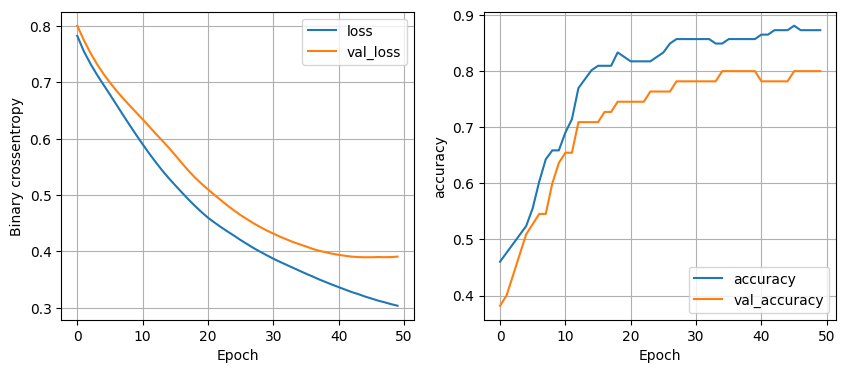


 Historia modelu max_accu 



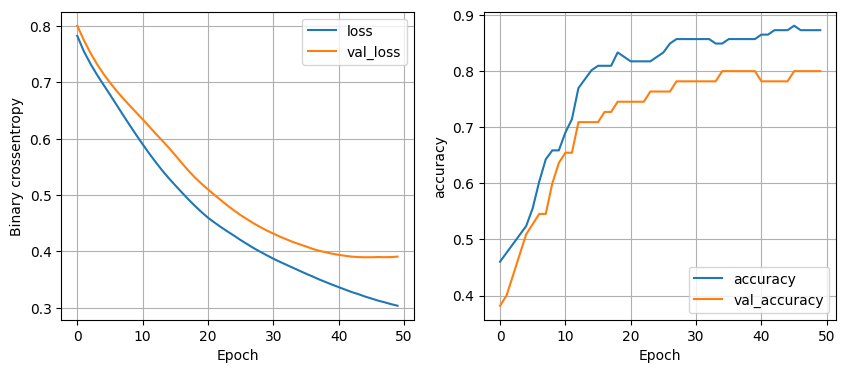

num_nodes = 8, dropout_prob = 0, lr = 0.001, batch_size = 16

 Historia modelu min_loss 



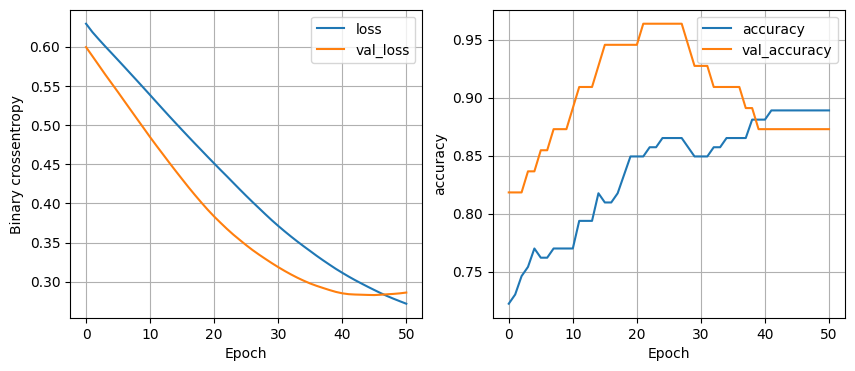


 Historia modelu max_accu 



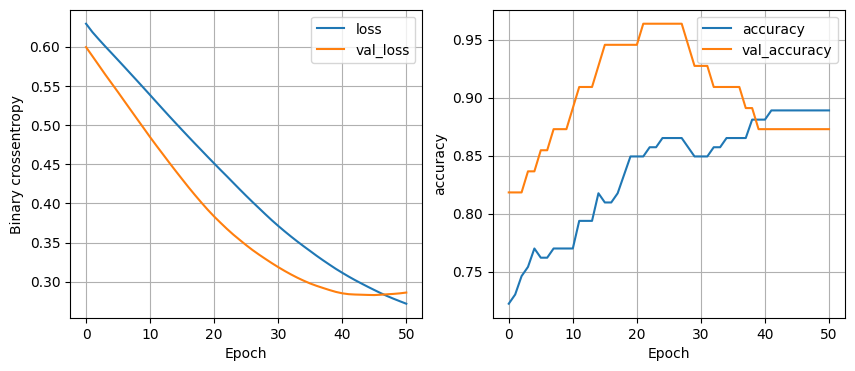

num_nodes = 8, dropout_prob = 0, lr = 0.001, batch_size = 32
num_nodes = 8, dropout_prob = 0, lr = 0.005, batch_size = 8
num_nodes = 8, dropout_prob = 0, lr = 0.005, batch_size = 16

 Historia modelu min_loss 



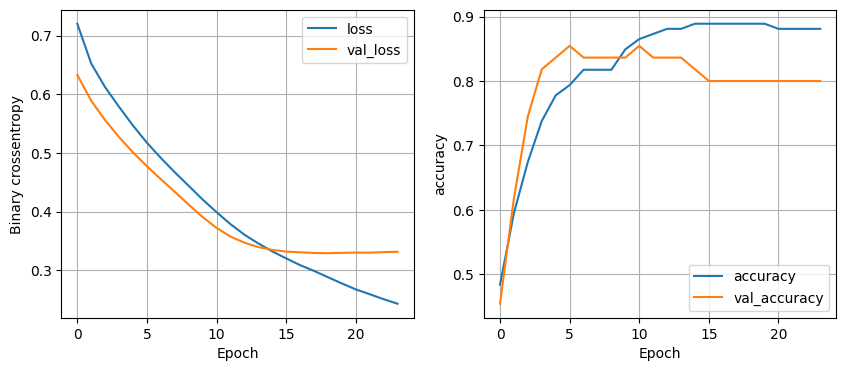

num_nodes = 8, dropout_prob = 0, lr = 0.005, batch_size = 32

 Historia modelu min_loss 



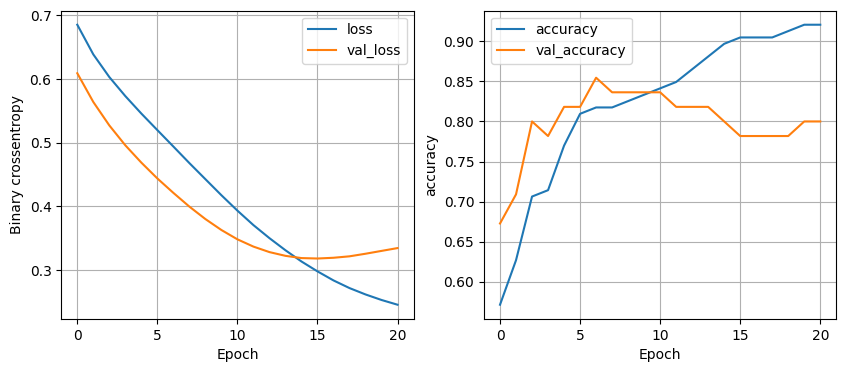

num_nodes = 8, dropout_prob = 0.1, lr = 0.001, batch_size = 8

 Historia modelu max_accu 



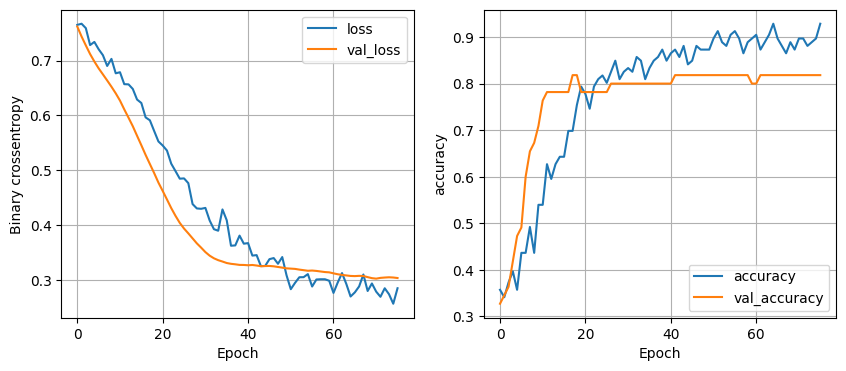

num_nodes = 8, dropout_prob = 0.1, lr = 0.001, batch_size = 16
num_nodes = 8, dropout_prob = 0.1, lr = 0.001, batch_size = 32

 Historia modelu max_accu 



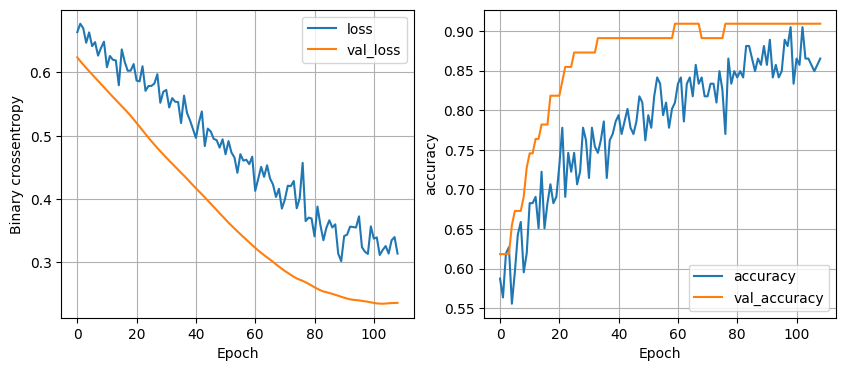

num_nodes = 8, dropout_prob = 0.1, lr = 0.005, batch_size = 8
num_nodes = 8, dropout_prob = 0.1, lr = 0.005, batch_size = 16
num_nodes = 8, dropout_prob = 0.1, lr = 0.005, batch_size = 32
num_nodes = 8, dropout_prob = 0.3, lr = 0.001, batch_size = 8
num_nodes = 8, dropout_prob = 0.3, lr = 0.001, batch_size = 16
num_nodes = 8, dropout_prob = 0.3, lr = 0.001, batch_size = 32
num_nodes = 8, dropout_prob = 0.3, lr = 0.005, batch_size = 8
num_nodes = 8, dropout_prob = 0.3, lr = 0.005, batch_size = 16
num_nodes = 8, dropout_prob = 0.3, lr = 0.005, batch_size = 32
num_nodes = 16, dropout_prob = 0, lr = 0.001, batch_size = 8
num_nodes = 16, dropout_prob = 0, lr = 0.001, batch_size = 16
num_nodes = 16, dropout_prob = 0, lr = 0.001, batch_size = 32
num_nodes = 16, dropout_prob = 0, lr = 0.005, batch_size = 8
num_nodes = 16, dropout_prob = 0, lr = 0.005, batch_size = 16
num_nodes = 16, dropout_prob = 0, lr = 0.005, batch_size = 32
num_nodes = 16, dropout_prob = 0.1, lr = 0.001, batch_size = 8
num

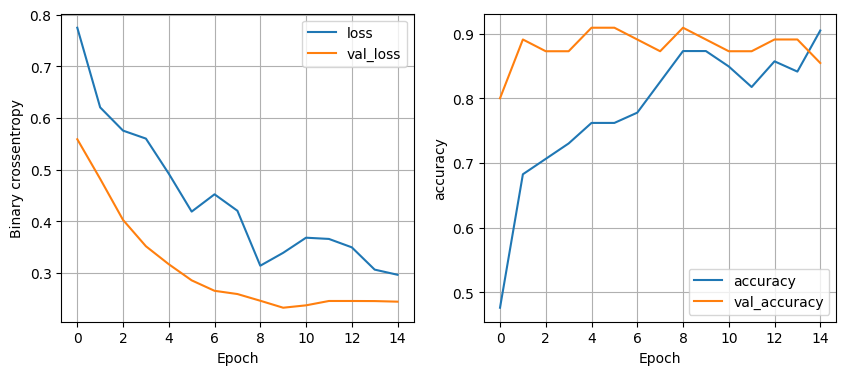

num_nodes = 16, dropout_prob = 0.3, lr = 0.005, batch_size = 16
num_nodes = 16, dropout_prob = 0.3, lr = 0.005, batch_size = 32

 Historia modelu max_accu 



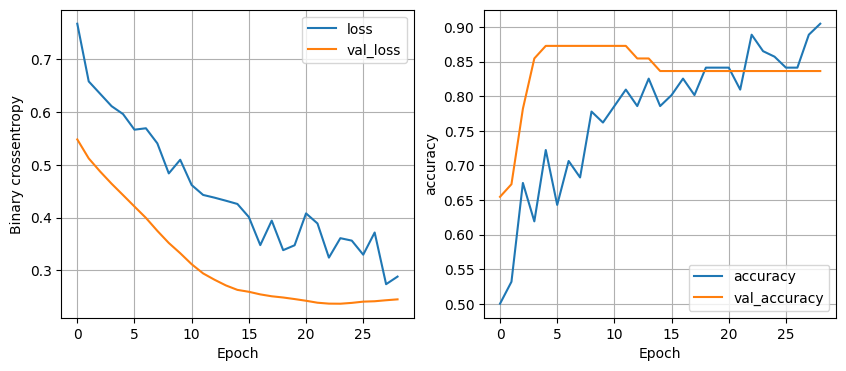

num_nodes = 32, dropout_prob = 0, lr = 0.001, batch_size = 8
num_nodes = 32, dropout_prob = 0, lr = 0.001, batch_size = 16
num_nodes = 32, dropout_prob = 0, lr = 0.001, batch_size = 32
num_nodes = 32, dropout_prob = 0, lr = 0.005, batch_size = 8
num_nodes = 32, dropout_prob = 0, lr = 0.005, batch_size = 16
num_nodes = 32, dropout_prob = 0, lr = 0.005, batch_size = 32
num_nodes = 32, dropout_prob = 0.1, lr = 0.001, batch_size = 8
num_nodes = 32, dropout_prob = 0.1, lr = 0.001, batch_size = 16
num_nodes = 32, dropout_prob = 0.1, lr = 0.001, batch_size = 32
num_nodes = 32, dropout_prob = 0.1, lr = 0.005, batch_size = 8
num_nodes = 32, dropout_prob = 0.1, lr = 0.005, batch_size = 16
num_nodes = 32, dropout_prob = 0.1, lr = 0.005, batch_size = 32
num_nodes = 32, dropout_prob = 0.3, lr = 0.001, batch_size = 8
num_nodes = 32, dropout_prob = 0.3, lr = 0.001, batch_size = 16
num_nodes = 32, dropout_prob = 0.3, lr = 0.001, batch_size = 32
num_nodes = 32, dropout_prob = 0.3, lr = 0.005, batch_siz

In [46]:
epochs = 200
function = 'relu'
results = []

parameters_min_loss_ReLU = []
parameters_max_accu_ReLU = []
tf.keras.utils.set_random_seed(42)

min_loss_ReLU = float('inf')
max_accu_ReLU = float('-inf')
min_loss_model_ReLU = None
max_accu_model_ReLU = None
min_loss_history_ReLU = None
max_accu_history_ReLU = None

for num_nodes in [8, 16, 32]:
  for dropout_prob in [0, 0.1, 0.3]:
    for lr in [0.001, 0.005]:
      for batch_size in [8, 16, 32]:
        print(f"num_nodes = {num_nodes}, dropout_prob = {dropout_prob}, lr = {lr}, batch_size = {batch_size}")
        tf.keras.backend.clear_session()
        model, history = train_model(X_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs, function)
        scores = model.evaluate(X_validation, y_validation, verbose = 0, return_dict=True)
        val_loss, val_accu = scores['loss'], scores['accuracy']
        results.append({
                'nodes': num_nodes, 'dropout': dropout_prob, 'lr': lr,
                'batch': batch_size, 'val_loss': val_loss,
                'val_accu': val_accu, 'epochs': len(history.history['loss']),
                'train_loss': history.history['loss'][-1],
                'train_accu': history.history['accuracy'][-1]})

        if val_loss < min_loss_ReLU:
          min_loss_ReLU = val_loss
          min_loss_model_ReLU = model
          min_loss_history_ReLU = history
          parameters_min_loss_ReLU = [num_nodes, dropout_prob, lr, batch_size]
          print("\n Historia modelu min_loss \n")
          plot_history(history)

        if val_accu > max_accu_ReLU:
          max_accu_ReLU = val_accu
          max_accu_model_ReLU = model
          max_accu_history_ReLU = history
          parameters_max_accu_ReLU = [num_nodes, dropout_prob, lr, batch_size]
          print("\n Historia modelu max_accu \n")
          plot_history(history)

#Grid Search dla funkcji Sigmoid

num_nodes = 8, dropout_prob = 0, lr = 0.001, batch_size = 8

 Historia modelu min_loss 



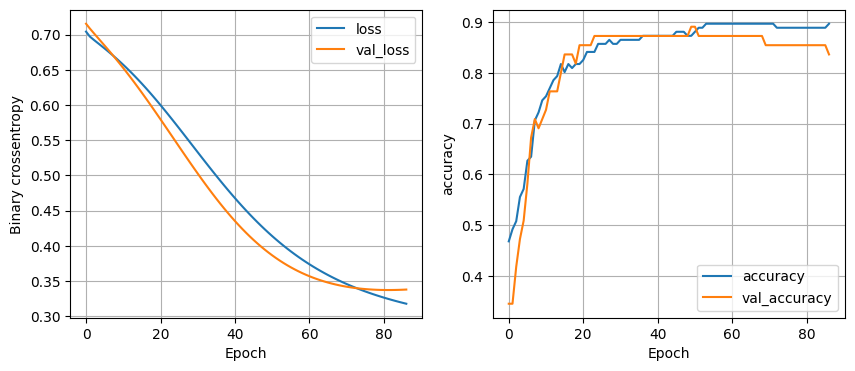


 Historia modelu max_accu 



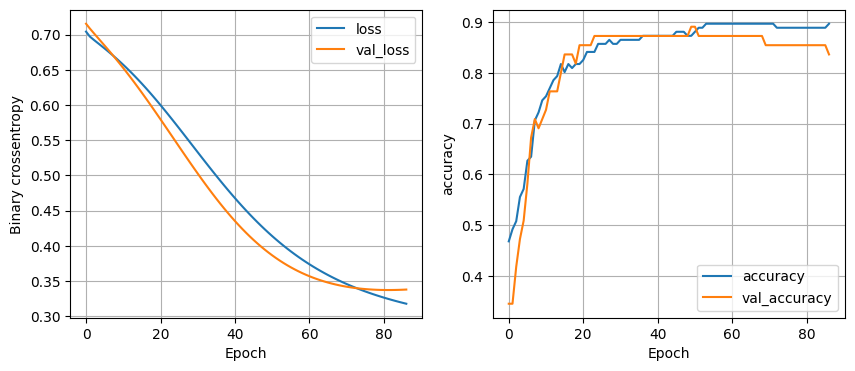

num_nodes = 8, dropout_prob = 0, lr = 0.001, batch_size = 16

 Historia modelu min_loss 



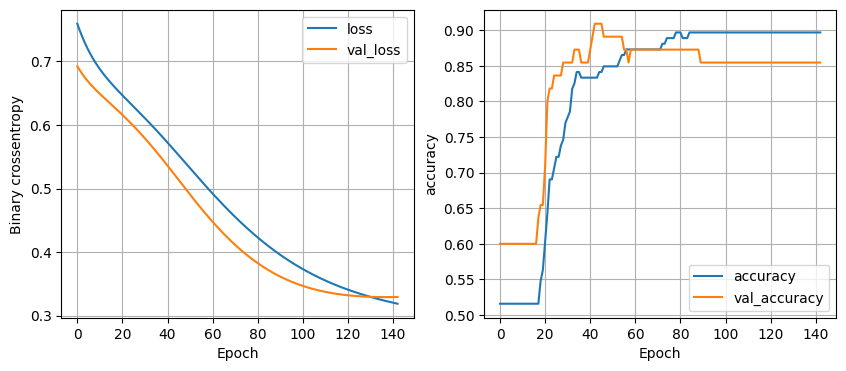

num_nodes = 8, dropout_prob = 0, lr = 0.001, batch_size = 32

 Historia modelu min_loss 



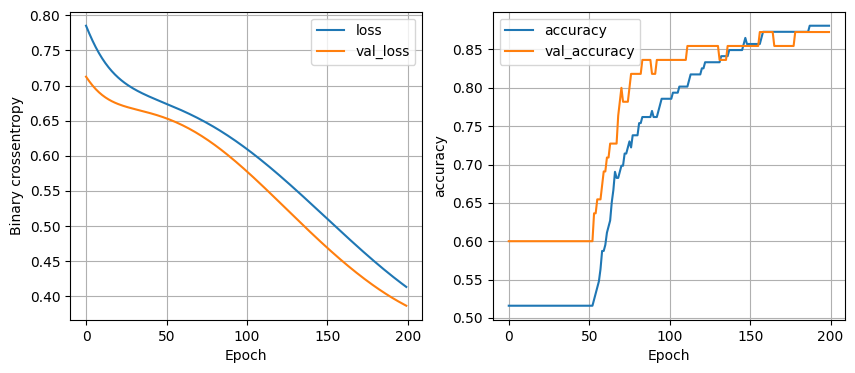


 Historia modelu max_accu 



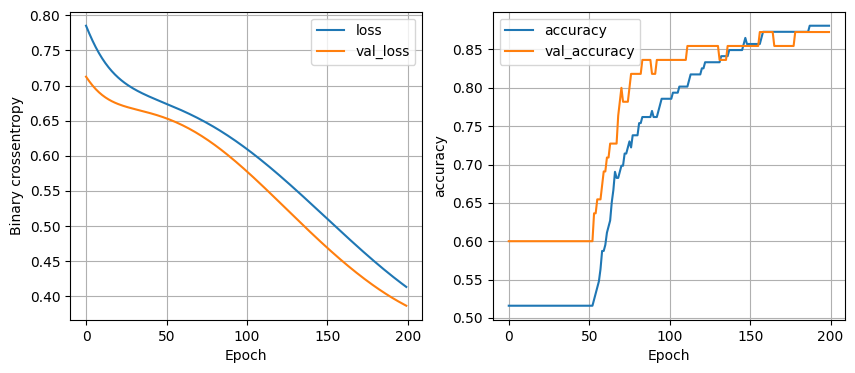

num_nodes = 8, dropout_prob = 0, lr = 0.005, batch_size = 8
num_nodes = 8, dropout_prob = 0, lr = 0.005, batch_size = 16

 Historia modelu min_loss 



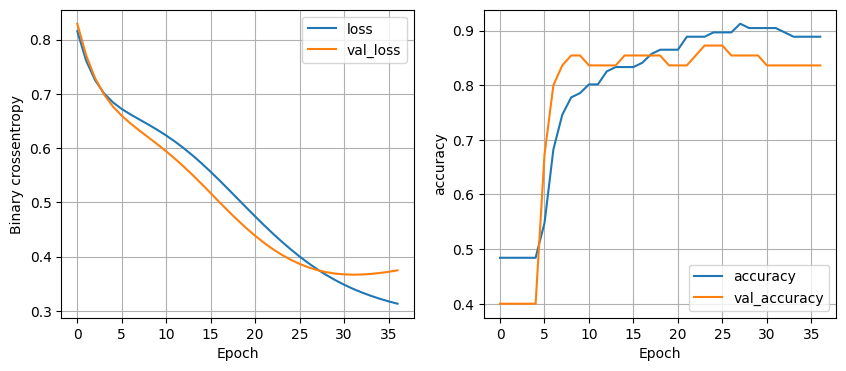

num_nodes = 8, dropout_prob = 0, lr = 0.005, batch_size = 32
num_nodes = 8, dropout_prob = 0.1, lr = 0.001, batch_size = 8
num_nodes = 8, dropout_prob = 0.1, lr = 0.001, batch_size = 16
num_nodes = 8, dropout_prob = 0.1, lr = 0.001, batch_size = 32

 Historia modelu min_loss 



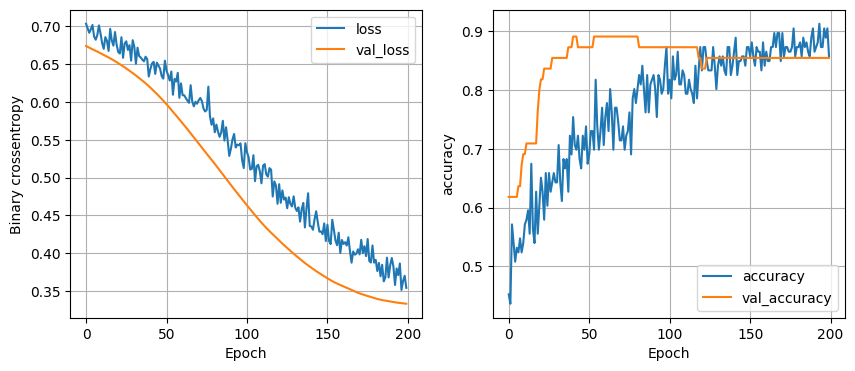

num_nodes = 8, dropout_prob = 0.1, lr = 0.005, batch_size = 8
num_nodes = 8, dropout_prob = 0.1, lr = 0.005, batch_size = 16
num_nodes = 8, dropout_prob = 0.1, lr = 0.005, batch_size = 32
num_nodes = 8, dropout_prob = 0.3, lr = 0.001, batch_size = 8
num_nodes = 8, dropout_prob = 0.3, lr = 0.001, batch_size = 16
num_nodes = 8, dropout_prob = 0.3, lr = 0.001, batch_size = 32
num_nodes = 8, dropout_prob = 0.3, lr = 0.005, batch_size = 8
num_nodes = 8, dropout_prob = 0.3, lr = 0.005, batch_size = 16

 Historia modelu min_loss 



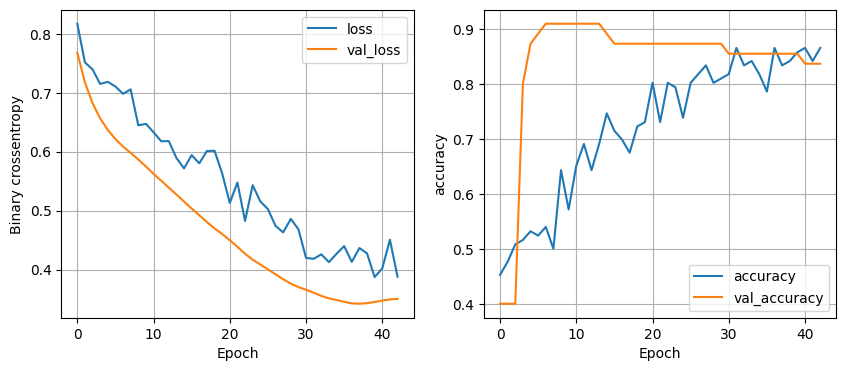

num_nodes = 8, dropout_prob = 0.3, lr = 0.005, batch_size = 32
num_nodes = 16, dropout_prob = 0, lr = 0.001, batch_size = 8
num_nodes = 16, dropout_prob = 0, lr = 0.001, batch_size = 16
num_nodes = 16, dropout_prob = 0, lr = 0.001, batch_size = 32
num_nodes = 16, dropout_prob = 0, lr = 0.005, batch_size = 8
num_nodes = 16, dropout_prob = 0, lr = 0.005, batch_size = 16
num_nodes = 16, dropout_prob = 0, lr = 0.005, batch_size = 32
num_nodes = 16, dropout_prob = 0.1, lr = 0.001, batch_size = 8
num_nodes = 16, dropout_prob = 0.1, lr = 0.001, batch_size = 16
num_nodes = 16, dropout_prob = 0.1, lr = 0.001, batch_size = 32
num_nodes = 16, dropout_prob = 0.1, lr = 0.005, batch_size = 8
num_nodes = 16, dropout_prob = 0.1, lr = 0.005, batch_size = 16
num_nodes = 16, dropout_prob = 0.1, lr = 0.005, batch_size = 32
num_nodes = 16, dropout_prob = 0.3, lr = 0.001, batch_size = 8
num_nodes = 16, dropout_prob = 0.3, lr = 0.001, batch_size = 16
num_nodes = 16, dropout_prob = 0.3, lr = 0.001, batch_size

In [58]:
epochs = 200
function = 'sigmoid'
results2 = []

parameters_min_loss_sigmoid = []
parameters_max_accu_sigmoid = []
tf.keras.utils.set_random_seed(42)

min_loss_sigmoid = float('inf')
max_accu_sigmoid = float('-inf')
min_loss_model_sigmoid = None
max_accu_model_sigmoid = None
min_loss_history_sigmoid = None
max_accu_history_sigmoid = None

for num_nodes in [8, 16, 32]:
  for dropout_prob in [0, 0.1, 0.3]:
    for lr in [0.001, 0.005]:
      for batch_size in [8, 16, 32]:
        print(f"num_nodes = {num_nodes}, dropout_prob = {dropout_prob}, lr = {lr}, batch_size = {batch_size}")
        tf.keras.backend.clear_session()
        model, history = train_model(X_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs, function)
        scores = model.evaluate(X_validation, y_validation, verbose = 0, return_dict=True)
        val_loss, val_accu = scores['loss'], scores['accuracy']
        results2.append({
                'nodes': num_nodes, 'dropout': dropout_prob, 'lr': lr,
                'batch': batch_size, 'val_loss': val_loss,
                'val_accu': val_accu, 'epochs': len(history.history['loss']),
                'train_loss': history.history['loss'][-1],
                'train_accu': history.history['accuracy'][-1]})
        if val_loss < min_loss_sigmoid:
          min_loss_sigmoid = val_loss
          min_loss_model_sigmoid = model
          min_loss_history_sigmoid = history
          parameters_min_loss_sigmoid = [num_nodes, dropout_prob, lr, batch_size]
          print("\n Historia modelu min_loss \n")
          plot_history(history)

        if val_accu > max_accu_sigmoid:
          max_accu_sigmoid = val_accu
          max_accu_model_sigmoid = model
          max_accu_history_sigmoid = history
          parameters_max_accu_sigmoid = [num_nodes, dropout_prob, lr, batch_size]
          print("\n Historia modelu max_accu \n")
          plot_history(history)

# Wyniki grid search dla funkcji ReLU

[16, 0.3, 0.005, 8]
[16, 0.3, 0.005, 32]
0.5097501873970032
0.8333333134651184


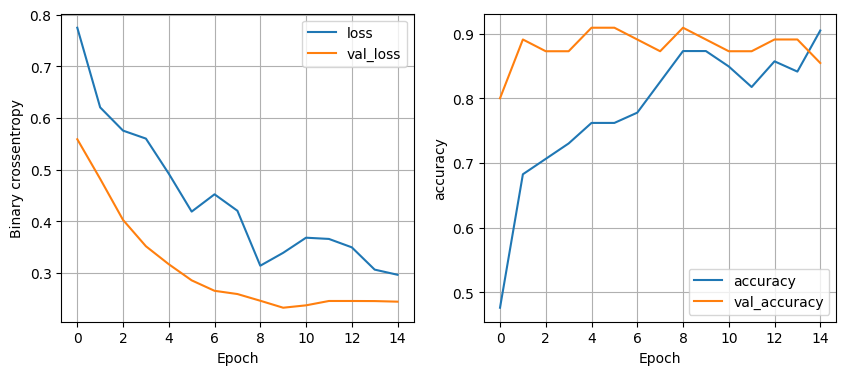

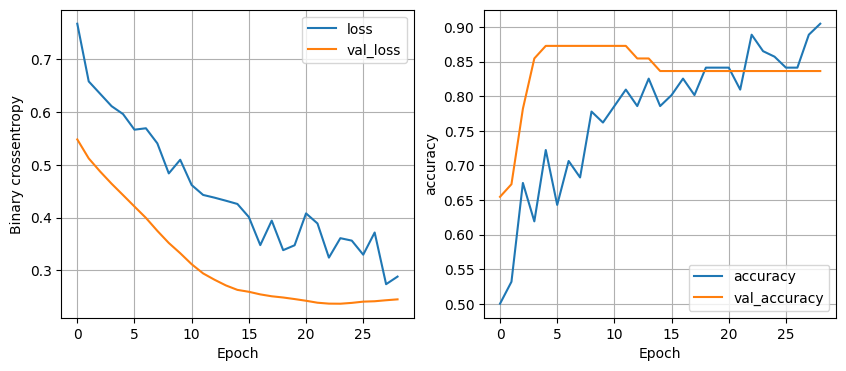

In [59]:
print(parameters_min_loss_ReLU)
print(parameters_max_accu_ReLU)
print(min_loss_ReLU)
print(max_accu_ReLU)
plot_history(min_loss_history_ReLU)
plot_history(max_accu_history_ReLU)

In [60]:
y_pred_min_loss_ReLU = min_loss_model_ReLU.predict(X_test)
y_pred_min_loss_ReLU = (y_pred_min_loss_ReLU > 0.5).astype(int).reshape(-1,)

y_pred_max_accu_ReLU = max_accu_model_ReLU.predict(X_test)
y_pred_max_accu_ReLU = (y_pred_max_accu_ReLU > 0.5).astype(int).reshape(-1,)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


In [61]:
print(classification_report(y_test, y_pred_min_loss_ReLU))
print(classification_report(y_test, y_pred_max_accu_ReLU))

              precision    recall  f1-score   support

           0       0.76      0.70      0.73        27
           1       0.78      0.82      0.80        34

    accuracy                           0.77        61
   macro avg       0.77      0.76      0.77        61
weighted avg       0.77      0.77      0.77        61

              precision    recall  f1-score   support

           0       0.74      0.74      0.74        27
           1       0.79      0.79      0.79        34

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61



#Wyniki grid search dla funkcji Sigmoid

[8, 0.3, 0.005, 16]
[8, 0, 0.001, 32]
0.5054983496665955
0.7833333611488342


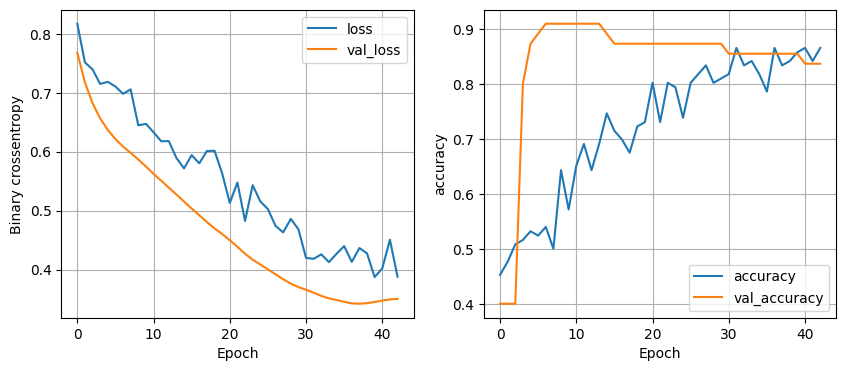

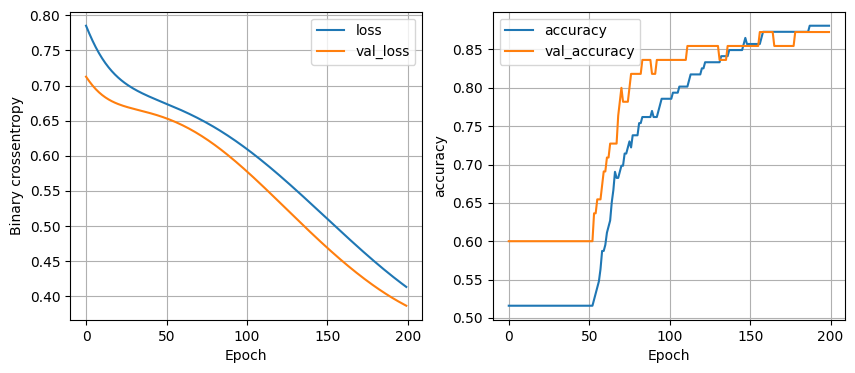

In [62]:
print(parameters_min_loss_sigmoid)
print(parameters_max_accu_sigmoid)
print(min_loss_sigmoid)
print(max_accu_sigmoid)
plot_history(min_loss_history_sigmoid)
plot_history(max_accu_history_sigmoid)

In [63]:
y_pred_min_loss_sigmoid = min_loss_model_sigmoid.predict(X_test)
y_pred_min_loss_sigmoid = (y_pred_min_loss_sigmoid > 0.5).astype(int).reshape(-1,)

y_pred_max_accu_sigmoid = max_accu_model_sigmoid.predict(X_test)
y_pred_max_accu_sigmoid = (y_pred_max_accu_sigmoid > 0.5).astype(int).reshape(-1,)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


In [64]:
print(classification_report(y_test, y_pred_min_loss_sigmoid))
print(classification_report(y_test, y_pred_max_accu_sigmoid))

              precision    recall  f1-score   support

           0       0.84      0.78      0.81        27
           1       0.83      0.88      0.86        34

    accuracy                           0.84        61
   macro avg       0.84      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61

              precision    recall  f1-score   support

           0       0.78      0.78      0.78        27
           1       0.82      0.82      0.82        34

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61

